In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

sns.set_theme(style="whitegrid")

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(os.path.join(PROJECT_ROOT, "src"))
from plotting_utils import save_fig

with open(os.path.join(PROJECT_ROOT, "config", "config.yaml")) as f:
    config = yaml.safe_load(f)

TABLES_DIR = os.path.join(PROJECT_ROOT, config["paths"]["tables_dir"])
FINAL_DIR = os.path.join(TABLES_DIR, "manuscript_final")
os.makedirs(FINAL_DIR, exist_ok=True)

In [2]:
pk_leak = pd.read_csv(os.path.join(TABLES_DIR, "pakistan_leakage_comparison.csv"))
ar_leak = pd.read_csv(os.path.join(TABLES_DIR, "arab5_leakage_comparison.csv"))
exclusions = pd.read_csv(os.path.join(TABLES_DIR, "leakage_audit_exclusions.csv"))

print("=== Pakistan: leaky vs. honest comparison ===")
print(pk_leak)
print("\n=== Arab5: leaky vs. honest comparison ===")
print(ar_leak)
print("\n=== Excluded variables ===")
print(exclusions)

pk_leak.to_csv(os.path.join(FINAL_DIR, "Table1a_pakistan_leakage_audit.csv"), index=False)
ar_leak.to_csv(os.path.join(FINAL_DIR, "Table1b_arab5_leakage_audit.csv"), index=False)
exclusions.to_csv(os.path.join(FINAL_DIR, "Table1c_exclusion_justification.csv"), index=False)

=== Pakistan: leaky vs. honest comparison ===
                                        Approach    Metric   Value  \
0  Published PERI_DEP claim (RNN-LSTM+SMOTE/GAN)  Accuracy  0.9500   
1    Reproduced leaky model (PHQ items -> label)  Accuracy  1.0000   
2        Trivial rule (Scalling >= 10), no model  Accuracy  1.0000   
3           Legitimate SDoH-only model (untuned)   AUC-ROC  0.5646   

  Uses outcome-defining items as predictors  
0                              Yes (likely)  
1                                       Yes  
2                         N/A (direct rule)  
3                                        No  

=== Arab5: leaky vs. honest comparison ===
                                            Approach    Metric   Value
0  Published Qasrawi et al. claim (Gradient Boost...  Accuracy  0.8330
1  Published Qasrawi et al. claim (Gradient Boost...  Accuracy  0.8290
2  Reproduced leaky model - depression (items -> ...  Accuracy  1.0000
3  Reproduced leaky model - anxiety (items ->

            dataset proposed_model  threshold  accuracy  macro_f1  auc_roc  \
0          pakistan             rf       0.51    0.5486    0.5329   0.5571   
1  arab5_depression             rf       0.55    0.6379    0.6314   0.6867   
2     arab5_anxiety             rf       0.45    0.7958    0.7228   0.7815   
3            uganda             rf       0.55    0.6364    0.6314   0.6965   

   auc_ci_lower  auc_ci_upper  
0        0.5353        0.5792  
1        0.6252        0.7468  
2        0.6958        0.8631  
3        0.6770        0.7162  
Saved figure: C:\maternal-mental-health-risk\reports\figures\manuscript_final\Figure1_master_results_forest_plot.png


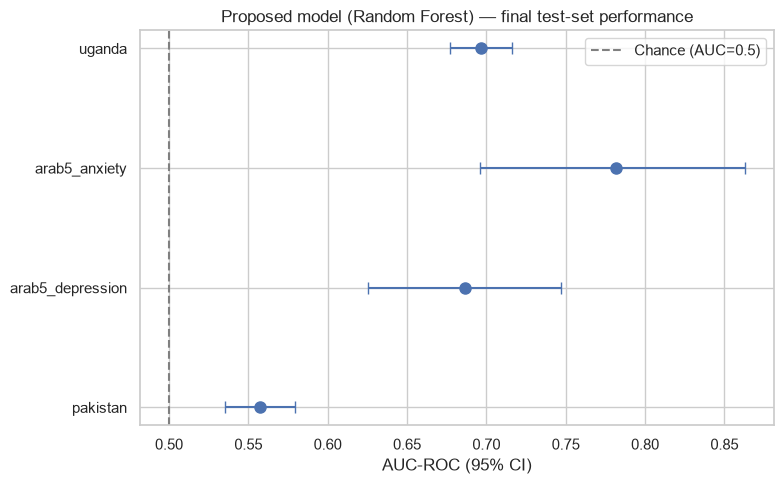

In [3]:
final_results = pd.read_csv(os.path.join(TABLES_DIR, "proposed_model_final_results.csv"))
print(final_results)
final_results.to_csv(os.path.join(FINAL_DIR, "Table2_final_proposed_model_results.csv"), index=False)

df = final_results.copy()
df["err_lower"] = df["auc_roc"] - df["auc_ci_lower"]
df["err_upper"] = df["auc_ci_upper"] - df["auc_roc"]

fig, ax = plt.subplots(figsize=(8, 5))
y_pos = np.arange(len(df))
ax.errorbar(df["auc_roc"], y_pos, xerr=[df["err_lower"], df["err_upper"]],
            fmt="o", capsize=4, color="#4C72B0", markersize=8)
ax.axvline(0.5, color="gray", linestyle="--", label="Chance (AUC=0.5)")
ax.set_yticks(y_pos)
ax.set_yticklabels(df["dataset"])
ax.set_xlabel("AUC-ROC (95% CI)")
ax.set_title("Proposed model (Random Forest) — final test-set performance")
ax.legend()
plt.tight_layout()
save_fig(fig, "Figure1_master_results_forest_plot.png", PROJECT_ROOT, dataset="manuscript_final")
plt.show()

In [4]:
rf_justification = pd.read_csv(os.path.join(TABLES_DIR, "rf_selection_justification.csv"))
print(rf_justification)
rf_justification.to_csv(os.path.join(FINAL_DIR, "Table3_rf_selection_justification.csv"), index=False)

            dataset  rf_oof_auc best_oof_model  best_oof_auc  rf_rank_among_7  \
0          pakistan      0.5382            svm        0.5418                3   
1  arab5_depression      0.6868             rf        0.6868                1   
2     arab5_anxiety      0.7718             rf        0.7718                1   
3            uganda      0.6913            xgb        0.6916                2   

   gap_to_best  
0       0.0036  
1       0.0000  
2       0.0000  
3       0.0002  


In [5]:
dl_vs_rf = pd.read_csv(os.path.join(TABLES_DIR, "dl_vs_rf_comparison.csv"))
dl_delta = pd.read_csv(os.path.join(TABLES_DIR, "dl_vs_rf_delta_auc.csv"))
print(dl_vs_rf)
print(dl_delta)

dl_vs_rf.to_csv(os.path.join(FINAL_DIR, "Table4a_dl_vs_rf_comparison.csv"), index=False)
dl_delta.to_csv(os.path.join(FINAL_DIR, "Table4b_dl_vs_rf_delta_auc.csv"), index=False)

            dataset  rf_auc  rf_ci_lower  rf_ci_upper  dl_auc  dl_ci_lower  \
0          pakistan  0.5571       0.5353       0.5792  0.5544       0.5315   
1  arab5_depression  0.6867       0.6252       0.7468  0.6754       0.6155   
2     arab5_anxiety  0.7815       0.6958       0.8631  0.7733       0.6861   
3            uganda  0.6965       0.6770       0.7162  0.6906       0.6708   

   dl_ci_upper  
0       0.5767  
1       0.7357  
2       0.8519  
3       0.7102  
            dataset  delta_auc_dl_minus_rf  ci_lower  ci_upper
0          pakistan                -0.0029   -0.0186    0.0133
1  arab5_depression                -0.0109   -0.0395    0.0168
2     arab5_anxiety                -0.0080   -0.0417    0.0270
3            uganda                -0.0059   -0.0142    0.0020


In [6]:
shap_files = {
    "pakistan": "pakistan_shap_top_features.csv",
    "arab5_depression": "arab5_depression_shap_top_features.csv",
    "arab5_anxiety": "arab5_anxiety_shap_top_features.csv",
    "uganda": "uganda_shap_top_features.csv",
}

shap_combined = []
for tag, fname in shap_files.items():
    df = pd.read_csv(os.path.join(TABLES_DIR, fname))
    df["dataset"] = tag
    df["rank"] = range(1, len(df) + 1)
    shap_combined.append(df[["dataset", "rank", "feature", "mean_abs_shap"]].head(10))

shap_combined_df = pd.concat(shap_combined, ignore_index=True)
print(shap_combined_df)
shap_combined_df.to_csv(os.path.join(FINAL_DIR, "Table5_shap_top10_all_datasets.csv"), index=False)

             dataset  rank                                        feature  \
0           pakistan     1         cat__Current Appereance Acceptance_Yes   
1           pakistan     2          cat__Current Appereance Acceptance_No   
2           pakistan     3  cat__Relationship with Mother in-law_Moderate   
3           pakistan     4                   cat__Female Education_Matric   
4           pakistan     5      cat__Relationship with Mother in-law_Good   
5           pakistan     6               cat__Working Status_Working Lady   
6           pakistan     7                 cat__Male Gender Preference_No   
7           pakistan     8            cat__Husband Education_Intermediate   
8           pakistan     9                cat__Male Gender Preference_Yes   
9           pakistan    10                  cat__Working Status_Housewife   
10  arab5_depression     1                       cat__StressduringCovid_1   
11  arab5_depression     2                       cat__StressduringCovid_0   

In [7]:
fairness_files = [f for f in os.listdir(TABLES_DIR) if "fairness" in f and f.endswith(".csv")]
print("Fairness tables found:", fairness_files)

fairness_combined = []
for fname in fairness_files:
    df = pd.read_csv(os.path.join(TABLES_DIR, fname))
    df["source_file"] = fname
    fairness_combined.append(df)

fairness_combined_df = pd.concat(fairness_combined, ignore_index=True)
fairness_combined_df.to_csv(os.path.join(FINAL_DIR, "Table6_fairness_all_subgroups.csv"), index=False)
print(f"\nCombined {len(fairness_combined_df)} rows across {len(fairness_files)} fairness tables")

Fairness tables found: ['arab5_anxiety_fairness_EducationLevel.csv', 'arab5_anxiety_fairness_FamilyIncome1.csv', 'arab5_depression_fairness_by_country.csv', 'arab5_depression_fairness_EducationLevel.csv', 'arab5_depression_fairness_FamilyIncome1.csv', 'pakistan_fairness_Female_Education.csv', 'pakistan_fairness_Sufficient_Money_for_Basic_Needs.csv', 'uganda_fairness_education.csv', 'uganda_fairness_occupation.csv']

Combined 31 rows across 9 fairness tables


In [8]:
harmonization_dist = pd.read_csv(os.path.join(TABLES_DIR, "harmonization_distribution_comparison.csv"))
external_val = pd.read_csv(os.path.join(TABLES_DIR, "cross_country_external_validation.csv"))

print(harmonization_dist)
print()
print(external_val)

harmonization_dist.to_csv(os.path.join(FINAL_DIR, "Table7a_harmonization_distributions.csv"), index=False)
external_val.to_csv(os.path.join(FINAL_DIR, "Table7b_external_validation_results.csv"), index=False)

            feature              level  pakistan_pct  arab5_pct
0         age_group            35_plus         13.26      15.15
1         age_group           under_35         86.74      84.85
2   education_group    above_secondary         28.23      78.57
3   education_group  secondary_or_less         71.77      21.43
4          employed           employed         26.00      37.58
5          employed       not_employed         74.00      62.42
6  financial_strain          no_strain         49.01      39.39
7  financial_strain             strain         50.99      60.61
8   first_pregnancy    first_pregnancy         26.02      33.58
9   first_pregnancy          not_first         73.98      66.42

           direction  internal_cv_auc  internal_calibration_auc  external_auc  \
0  pakistan_to_arab5           0.5230                    0.5171        0.4802   
1  arab5_to_pakistan           0.5695                    0.5726        0.4876   

   external_auc_ci_lower  external_auc_ci_upper  ex

In [9]:
print("=== Manuscript-ready tables saved to reports/tables/manuscript_final/ ===\n")
for fname in sorted(os.listdir(FINAL_DIR)):
    path = os.path.join(FINAL_DIR, fname)
    df = pd.read_csv(path)
    print(f"{fname}: {df.shape[0]} rows x {df.shape[1]} cols")

print("\n=== Figures available in reports/figures/ ===")
figures_dir = os.path.join(PROJECT_ROOT, config["paths"]["figures_dir"])
for subdir in sorted(os.listdir(figures_dir)):
    full = os.path.join(figures_dir, subdir)
    if os.path.isdir(full):
        pngs = [f for f in os.listdir(full) if f.endswith(".png")]
        print(f"  {subdir}/: {len(pngs)} figures")

=== Manuscript-ready tables saved to reports/tables/manuscript_final/ ===

Table1a_pakistan_leakage_audit.csv: 4 rows x 4 cols
Table1b_arab5_leakage_audit.csv: 5 rows x 3 cols
Table1c_exclusion_justification.csv: 6 rows x 3 cols
Table2_final_proposed_model_results.csv: 4 rows x 8 cols
Table3_rf_selection_justification.csv: 4 rows x 6 cols
Table4a_dl_vs_rf_comparison.csv: 4 rows x 7 cols
Table4b_dl_vs_rf_delta_auc.csv: 4 rows x 4 cols
Table5_shap_top10_all_datasets.csv: 40 rows x 4 cols
Table6_fairness_all_subgroups.csv: 31 rows x 7 cols
Table7a_harmonization_distributions.csv: 10 rows x 4 cols
Table7b_external_validation_results.csv: 2 rows x 11 cols

=== Figures available in reports/figures/ ===
  arab5/: 6 figures
  arab5_anxiety/: 6 figures
  arab5_depression/: 6 figures
  cross_country/: 1 figures
  manuscript_final/: 1 figures
  pakistan/: 11 figures
  postnatal/: 3 figures
  uganda/: 12 figures
